In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from altmin import fit_altmin
from functools import partial
from skimage.metrics import peak_signal_noise_ratio as psnr
import matplotlib.pyplot as plt

## Processing Data

In [2]:
# with np.load('img_utils/plane_data_new.npz') as data:
with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']

In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
print(x, y, frames)

70 100 90


In [5]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

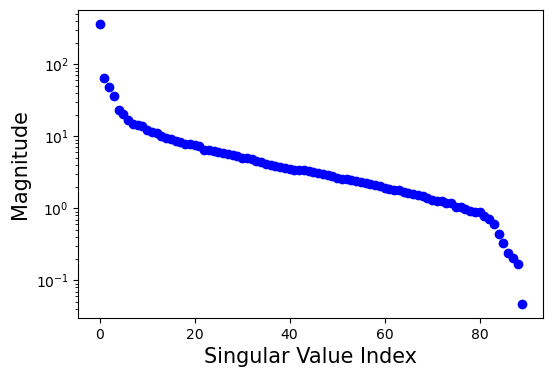

In [6]:
s = np.linalg.svd(vec_data)
fig, ax = plt.subplots(figsize=(6, 4))  # Width = 8, Height = 6 (inches)

# Plot the explained variance
ax.scatter(np.arange(s[1].shape[0]), s[1], marker='o', color='b')

# Add titles and labels
ax.set_xlabel(rf'Singular Value Index', fontsize=15)
ax.set_ylabel('Magnitude', fontsize=15)
ax.set_yscale('log')
# ax.legend(fontsize=12)
fig.savefig('mouse_svals.png', dpi=500, bbox_inches="tight")

In [7]:
data.shape

(70, 100, 90)

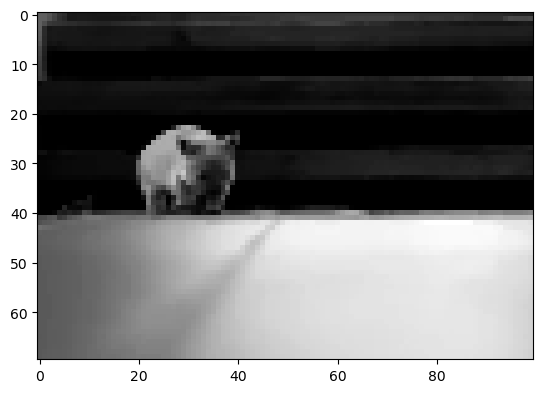

In [8]:
plt.imshow(data[:, :, 10], cmap='gray')

In [9]:
Xs = []

ell = 4 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [10]:
def spectral_init(Ys, frac_observed):
    """
    Performing spectral initialization for missing data case.
    """

    T = len(Ys)
    ell = Ys[0].shape[1]
    
    Xs_init = []

    for t in range(T):
        temp = []
        for i in range(ell):
            spect_mat = np.expand_dims( (1 / frac_observed)*Ys[t][:, i], axis=1 )
            temp.append( np.expand_dims(np.linalg.svd(spect_mat)[0][:, 0], axis=1) )

        Xs_init.append(np.concatenate(temp, axis=1))
        
    return Xs_init

In [11]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]


def recovery(Xs, true_Xs):
    """
    Function for computing objective function value.
    """

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Driver Code

In [12]:
FRAC_OBSERVED = 0.5
SIGMA = 0.01

NTRIALS = 1
NITERS = 0
RANK = 3



In [13]:
psnr_k_geodesic = np.zeros((NTRIALS, ))
ssim_k_geodesic = np.zeros((NTRIALS, ))
rmse_k_geodesic = np.zeros((NTRIALS, ))

for trial in range( NTRIALS ):
    print('Trial Number: ', trial)

    # Generating data
    forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

    # Generate masked data
    Ys = []

    for i, Xi in enumerate(Xs):
        Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

    # Initializing
    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
    geo = init_geodesic(d=x*y, k=RANK, Xs=Xs_init, init="pca") # Initialize geodesic
    ts = np.linspace(0.0, 1.0, T+60, endpoint=False)[30:-30]  # Timestamps

    data_init = {
    "Xs":            Xs_init,
    "ts":            ts,
    "measurements":  Ys,
    "forward":       forward,
    "transpose":     transpose,
    "masks":         masks,
    }
        
    # Initial computations
    rmse_k_geodesic[trial, ] = compute_RMSE(data_init["Xs"], Xs)
    psnr_k_geodesic[trial, ] = compute_PSNR(data_init["Xs"], Xs)
    ssim_k_geodesic[trial, ] = compute_SSIM(data_init["Xs"], Xs)
        
    def callback(itr, geo, data):
        cur_rmse = compute_RMSE(data["Xs"], Xs)
        cur_psnr = compute_PSNR(data["Xs"], Xs)
        cur_ssim = compute_SSIM(data["Xs"], Xs)
        
        #if cur_rmse < rmse_k_geodesic[trial, ]:
        #if cur_psnr > psnr_k_geodesic[trial, ]:
        if True:
            rmse_k_geodesic[trial, ] = cur_rmse
            psnr_k_geodesic[trial, ] = cur_psnr
            ssim_k_geodesic[trial, ] = cur_ssim
        else:
            return True
    
        #if itr == NITERS - 1:
        print('(k-Geodesic) Iteration:', itr, 'PSNR:', psnr_k_geodesic[trial,], 'SSIM:', ssim_k_geodesic[trial, ], 'RMSE Error:', rmse_k_geodesic[trial, ])  

        return False

    estimator = GeodesicEstimator(rank=RANK)
    geo_mm_est = estimator.fit(
                    geo=geo,
                    data=data_init,
                    callback=callback,
                    niters=NITERS, 
                    lambda_fn=1.0,           
    )

Trial Number:  0


In [14]:
X_geo_concat = np.concatenate(geo_mm_est[1]["Xs"], axis=1)
X_concat = np.concatenate(Xs, axis=1)

## GROUSE Baseline

Grassmannian Rank-One Update Subspace Estimation (Balzano, Nowak & Recht, 2010),
implemented for the missing-data / matrix-completion case. GROUSE processes one
incomplete column at a time, takes a rank-one geodesic step on the Grassmannian to
update its subspace estimate, and (after a few passes over the columns) completes the
matrix by projecting each observed column onto the learned subspace.

In [15]:
import numpy as np

def grouse_update(U, idx, v_obs, step):
    """One GROUSE rank-one geodesic update (Algorithm 1, Balzano-Nowak-Recht 2010).

    U      : (n, r) current orthonormal basis estimate
    idx    : observed coordinate indices for this column (the support Omega)
    v_obs  : (|Omega|,) observed entries of the column on `idx`
    step   : geodesic step length eta
    """
    U_Omega = U[idx, :]
    w, *_ = np.linalg.lstsq(U_Omega, v_obs, rcond=None)   # Step 2: weights
    p = U @ w                                             # Step 3: full prediction p = U w
    r = np.zeros(U.shape[0])                              # Step 4: residual on observed support
    r[idx] = v_obs - p[idx]
    rnorm, pnorm, wnorm = np.linalg.norm(r), np.linalg.norm(p), np.linalg.norm(w)
    if rnorm < 1e-12 or pnorm < 1e-12 or wnorm < 1e-12:
        return U, w
    sigma = rnorm * pnorm                                 # Step 5: sigma = ||r|| ||p||
    theta = sigma * step
    direction = (np.cos(theta) - 1.0) * (p / pnorm) + np.sin(theta) * (r / rnorm)
    return U + np.outer(direction, w / wnorm), w


def grouse(Y, M, rank, n_passes=20, C=2.0, step_rule="diminishing",
           U0=None, shuffle=True, seed=0):
    """GROUSE for matrix completion (Sec. 4.2). Tracks the column subspace from
    incomplete columns, then completes the matrix by projecting each observed
    column onto the learned subspace.

        Y : (n, N) measurements      M : (n, N) binary mask of observed entries

    Only entries where M != 0 are used (Y may carry noise off the support).
    step_rule : "diminishing" (eta = C/t, paper Fig. 5) or "constant" (eta = C).
    Returns (X_hat, U).
    """
    rng = np.random.default_rng(seed)
    n, N = Y.shape
    U = np.linalg.qr(rng.standard_normal((n, rank)) if U0 is None else U0)[0]
    t = 0
    for _ in range(n_passes):
        order = rng.permutation(N) if shuffle else np.arange(N)
        for j in order:
            idx = np.flatnonzero(M[:, j])
            if idx.size <= rank:            # need |Omega| > rank for a full-rank LS
                continue
            t += 1
            step = C / t if step_rule == "diminishing" else C
            U, _ = grouse_update(U, idx, Y[idx, j], step)
    X_hat = np.zeros((n, N))                 # complete via projection onto learned subspace
    for j in range(N):
        idx = np.flatnonzero(M[:, j])
        if idx.size == 0:
            continue
        w, *_ = np.linalg.lstsq(U[idx, :], Y[idx, j], rcond=None)
        X_hat[:, j] = U @ w
    return X_hat, U


In [16]:
# Build (d, N) measurement / mask matrices from the per-block lists used above.
# (Y is noisy off the support, so the mask -- not the nonzeros of Y -- defines what is observed.)
Y_mat = np.concatenate(Ys, axis=1)
M_mat = np.concatenate(masks, axis=1).astype(float)

print("RANK:", RANK)
# The geodesic step size is GROUSE's one free parameter and is data-scale dependent
# (the paper stresses this). Sweep a few values per rule and keep the best
# reconstruction -- mirroring how the geodesic callback above keeps its best iterate.
grouse_candidates = [("diminishing", C) for C in (0.01, 0.05, 0.1, 0.5, 1,10, 30, 100)] \
                  + [("constant",    C) for C in (1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1)]

best_err, best_cfg, grouse_soln, grouse_U = np.inf, None, None, None
for rule, C in grouse_candidates:
    Xh, Uh = grouse(Y_mat, M_mat, rank=2*RANK, n_passes=10, C=C, step_rule=rule, seed=0)
    err = np.linalg.norm(Xh - X_concat) / np.linalg.norm(X_concat)
    if err < best_err:
        best_err, best_cfg, grouse_soln, grouse_U = err, (rule, C), Xh, Uh

print(f"GROUSE best step: rule={best_cfg[0]}, C={best_cfg[1]}, rel-Frob err={best_err:.4e}")


RANK: 3
GROUSE best step: rule=diminishing, C=0.5, rel-Frob err=2.3664e-01


### GROUSE metrics across trials

Scored with the imported `compute_PSNR` / `compute_SSIM` / `compute_RMSE` (same as the geodesic estimator), with mean and standard deviation over `NTRIALS` trials.

In [17]:
# GROUSE across trials: score with the imported metric functions
# (compute_PSNR / compute_SSIM / compute_RMSE), exactly as the geodesic estimator
# is evaluated above. Each trial regenerates masks + noisy measurements, runs GROUSE
# with the same step-size sweep, then scores the completed matrix. The metric
# functions take a list of (d, ell) blocks, so we split GROUSE's (d, N) output back
# into blocks first.

def to_blocks(X_mat, ell):
    """Split a (d, N) matrix into the list of (d, ell) blocks the metrics expect."""
    n_blocks = X_mat.shape[1] // ell
    return [X_mat[:, t * ell:(t + 1) * ell] for t in range(n_blocks)]

psnr_grouse = np.zeros((NTRIALS, ))
ssim_grouse = np.zeros((NTRIALS, ))
rmse_grouse = np.zeros((NTRIALS, ))

grouse_candidates = [("diminishing", C) for C in (0.01, 0.05, 0.1, 0.5, 1, 10, 30, 100)] \
                  + [("constant",    C) for C in (1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1)]

for trial in range(NTRIALS):
    print('Trial Number: ', trial)

    # Generate data for this trial (same observation model as the geodesic driver).
    forward_t, transpose_t, masks_t = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,
                                                  frac_observed=FRAC_OBSERVED)
    Ys_t = [forward_t(Xi, masks_t[i]) + np.random.randn(*Xi.shape) * SIGMA
            for i, Xi in enumerate(Xs)]

    Y_mat_t = np.concatenate(Ys_t, axis=1)
    M_mat_t = np.concatenate(masks_t, axis=1).astype(float)

    # Sweep the step size and keep the best reconstruction (as in the runner above).
    best_err, best_soln = np.inf, None
    for rule, C in grouse_candidates:
        Xh, _ = grouse(Y_mat_t, M_mat_t, rank=2*RANK, n_passes=100, C=C,
                       step_rule=rule, seed=trial)
        err = np.linalg.norm(Xh - X_concat) / np.linalg.norm(X_concat)
        if err < best_err:
            best_err, best_soln = err, Xh

    # Score with the imported metric functions (estimate first, ground truth second).
    grouse_blocks = to_blocks(best_soln, ell)
    psnr_grouse[trial, ] = compute_PSNR(grouse_blocks, Xs)
    ssim_grouse[trial, ] = compute_SSIM(grouse_blocks, Xs)
    rmse_grouse[trial, ] = compute_RMSE(grouse_blocks, Xs)

    print('(GROUSE) Trial:', trial, 'PSNR:', psnr_grouse[trial, ],
          'SSIM:', ssim_grouse[trial, ], 'RMSE:', rmse_grouse[trial, ])


Trial Number:  0
(GROUSE) Trial: 0 PSNR: 20.73409873602026 SSIM: 0.6577820254843445 RMSE: 0.10858705833593495


In [18]:
# Mean and standard deviation across trials for GROUSE.
print('(GROUSE) PSNR:', np.mean(psnr_grouse), np.std(psnr_grouse))
print('(GROUSE) SSIM:', np.mean(ssim_grouse), np.std(ssim_grouse))
print('(GROUSE) RMSE:', np.mean(rmse_grouse), np.std(rmse_grouse))


(GROUSE) PSNR: 20.73409873602026 0.0
(GROUSE) SSIM: 0.6577820254843445 0.0
(GROUSE) RMSE: 0.10858705833593495 0.0


In [19]:
geo_psnrs = []
geo_psnrs_orig = []

ksvd_psnrs = []
twoksvd_psnrs = []
grouse_psnrs = []

for idx in range(X_geo_concat.shape[1]):
    geo_psnrs.append(psnr(normalize_np(X_geo_concat[:, idx]), normalize_np(X_concat[:, idx])))
    grouse_psnrs.append( psnr(normalize_np(grouse_soln[:, idx]), normalize_np(X_concat[:, idx]) ) )
                    
    print(idx, geo_psnrs[-1], grouse_psnrs[-1])

0 11.861004716526322 17.700755374819156
1 11.7703018781616 17.54259450071706
2 11.745483120880415 17.503019368601286
3 11.766136071731957 17.53128409820286
4 11.792697765306709 17.61364554676526
5 11.835294737199376 17.71363288138813
6 11.68634867021157 17.765146924231214
7 11.824507418048654 17.736721950099085
8 11.84851688064473 17.636285095068796
9 11.790934871954683 17.738863099143238
10 11.927059931291017 17.63490512866047
11 11.628579126957518 17.35406698271084
12 11.737978778959718 17.628004790282244
13 11.610188414587 17.47361202555011
14 11.69490022240138 17.743421227158617
15 11.569356445492655 17.480667073945742
16 11.618573004245382 17.56775484122485
17 11.537501022090023 17.41317144130255
18 11.78068975713321 17.474431025805853
19 11.609356499801862 17.67634448240441
20 11.589309509200998 17.815544753322087
21 11.613614342332674 17.98284249805367
22 11.634057645585212 17.896598620289744
23 11.654178479367426 17.97727970046162
24 11.726559450127844 18.413347146893784
25 11.

In [20]:
np.mean(geo_psnrs)

12.214381391124414

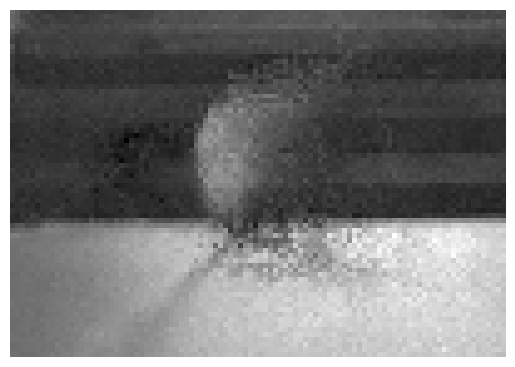

In [25]:
idx = 50
plt.imshow(np.reshape(grouse_soln[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'grouse_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [26]:
print(psnr(normalize_np(grouse_soln[:, idx]), normalize_np(X_concat[:, idx])))


16.096586924791787
